In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
online_retails = pd.read_excel('online-retails.xlsx')
online_retails_copy = online_retails.copy(deep=True)

# Data Inspection

In [179]:
online_retails.shape

(541909, 8)

In [5]:
online_retails_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:
online_retails_copy.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


In [7]:
online_retails_copy.sample(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
140246,548388,21166,COOK WITH WINE METAL SIGN,3,2011-03-30 16:52:00,2.08,13268.0,United Kingdom
377929,569571,23352,ROLL WRAP 50'S RED CHRISTMAS,72,2011-10-05 10:09:00,1.04,16684.0,United Kingdom
70043,541997,16014,SMALL CHINESE STYLE SCISSOR,10,2011-01-25 10:38:00,0.42,18077.0,United Kingdom
267171,560288,21755,LOVE BUILDING BLOCK WORD,3,2011-07-18 10:05:00,5.95,15845.0,United Kingdom
306892,563849,23047,PAPER LANTERN 5 POINT SEQUIN STAR,2,2011-08-19 15:04:00,5.75,14772.0,United Kingdom


In [8]:
online_retails_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


### Online Retails Data Description

- **InvoiceNo**: Invoice number. A unique number for each transaction (invoice). If this code starts with "c", it indicates that the transaction has been canceled.
- **StockCode**: A 5-digit integral number uniquely assigned to each distinct product.
- **Description**: Name of the product.
- **Quantity**: Quantity of the product. It defines how many products are sold in the invoices.
- **InvoiceDate**: Invoice date and time.
- **UnitPrice**: Product price (in GBP - British Pounds).
- **CustomerID**: A 5-digit integral number uniquely assigned to each customer	.
- **Country**: The name of the country where the customer lives.

In [10]:
stats= online_retails_copy.describe()

In [11]:
stats

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [12]:
Q1_Quantity = stats.Quantity['25%']
Q3_Quantity = stats.Quantity['75%']

In [13]:
IQR_Quantity = Q3_Quantity-Q1_Quantity
IQR_Quantity

9.0

In [14]:
lower_bound_quantity = Q1_Quantity-1.5*IQR_Quantity
upper_bound_quantity = Q3_Quantity+1.5*IQR_Quantity
print(lower_bound_quantity)
print(upper_bound_quantity)

-12.5
23.5


In [15]:
Q1_unit = stats.Quantity['25%']
Q3_unit = stats.Quantity['75%']
IQR_unit = Q3_unit-Q1_unit
IQR_unit
lower_bound_unit = Q1_unit-1.5*IQR_unit
upper_bound_unit = Q3_unit+1.5*IQR_unit
print(lower_bound_unit)
print(upper_bound_unit)

-12.5
23.5


In [16]:
stats.InvoiceDate

count                           541909
mean     2011-07-04 13:34:57.156386048
min                2010-12-01 08:26:00
25%                2011-03-28 11:34:00
50%                2011-07-19 17:17:00
75%                2011-10-19 11:27:00
max                2011-12-09 12:50:00
std                                NaN
Name: InvoiceDate, dtype: object

# Missing Data Handling and cleaning

In [18]:
(online_retails_copy.isnull().sum()/online_retails_copy.shape[0])*100

InvoiceNo       0.000000
StockCode       0.000000
Description     0.268311
Quantity        0.000000
InvoiceDate     0.000000
UnitPrice       0.000000
CustomerID     24.926694
Country         0.000000
dtype: float64

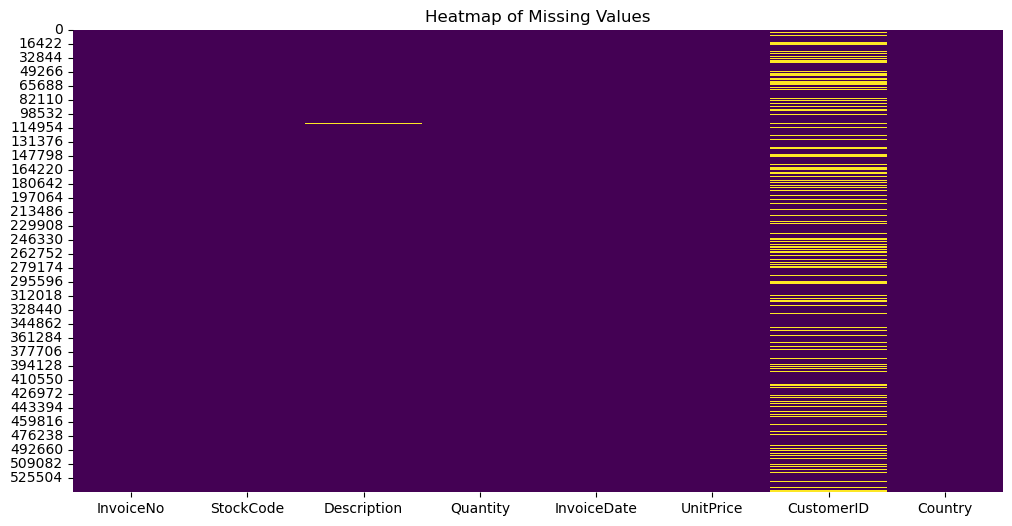

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [19]:
# Heatmap to visualize missing values
plt.figure(figsize=(12, 6))
sns.heatmap(online_retails_copy.isnull(), cbar=False, cmap='viridis')
plt.title('Heatmap of Missing Values')
plt.show()

# to show count of missing values
print(online_retails.isnull().sum())

In [20]:
online_retails_copy.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [21]:
# Convert 'InvoiceNo' to string type (if not already)
online_retails_copy['InvoiceNo'] = online_retails_copy['InvoiceNo'].astype(str)

# Filter the dataset to get rows where 'InvoiceNo' starts with 'C' or 'c'
cancelled_items = online_retails_copy[online_retails_copy['InvoiceNo'].str.startswith('c')]

# Display the cancelled items
cancelled_items

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [22]:
online_retails_copy = online_retails_copy.dropna(subset = ['CustomerID', 'Description'])

In [23]:
online_retails_copy.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [24]:
online_retails_copy.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

In [25]:
online_retails_copy = online_retails_copy.dropna(subset=['CustomerID'])
online_retails_copy['CustomerID'] = online_retails_copy['CustomerID'].astype('int64')

In [26]:
online_retails_copy['CustomerID']

0         17850
1         17850
2         17850
3         17850
4         17850
          ...  
541904    12680
541905    12680
541906    12680
541907    12680
541908    12680
Name: CustomerID, Length: 406829, dtype: int64

In [27]:
online_retails_copy['CustomerID'].value_counts()

CustomerID
17841    7983
14911    5903
14096    5128
12748    4642
14606    2782
         ... 
15070       1
15753       1
17065       1
16881       1
16995       1
Name: count, Length: 4372, dtype: int64

In [28]:
online_retails_copy.duplicated().sum()

5225

In [29]:
online_retails_copy.drop_duplicates(inplace = True)

In [30]:
online_retails_copy.shape

(401604, 8)

# Data Visualisation

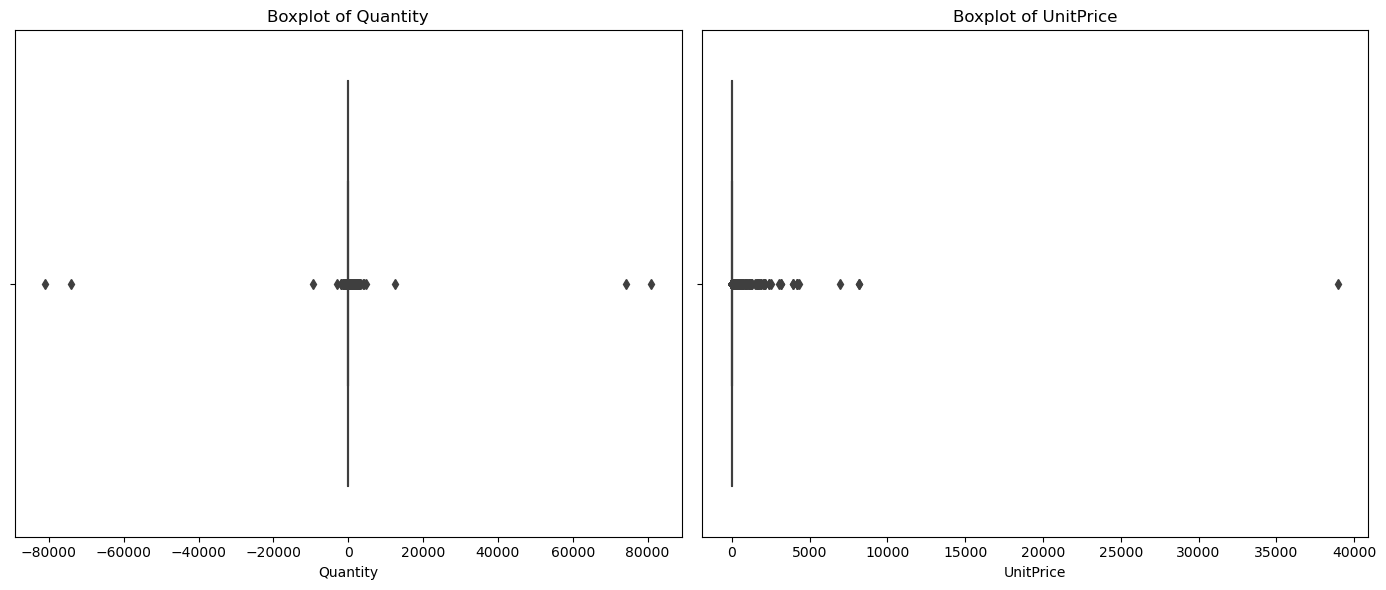

In [32]:
# Boxplots for detecting outliers in Quantity and UnitPrice
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.boxplot(data=online_retails_copy, x='Quantity')
plt.title('Boxplot of Quantity')

plt.subplot(1, 2, 2)
sns.boxplot(data=online_retails_copy, x='UnitPrice')
plt.title('Boxplot of UnitPrice')

plt.tight_layout()
plt.show()


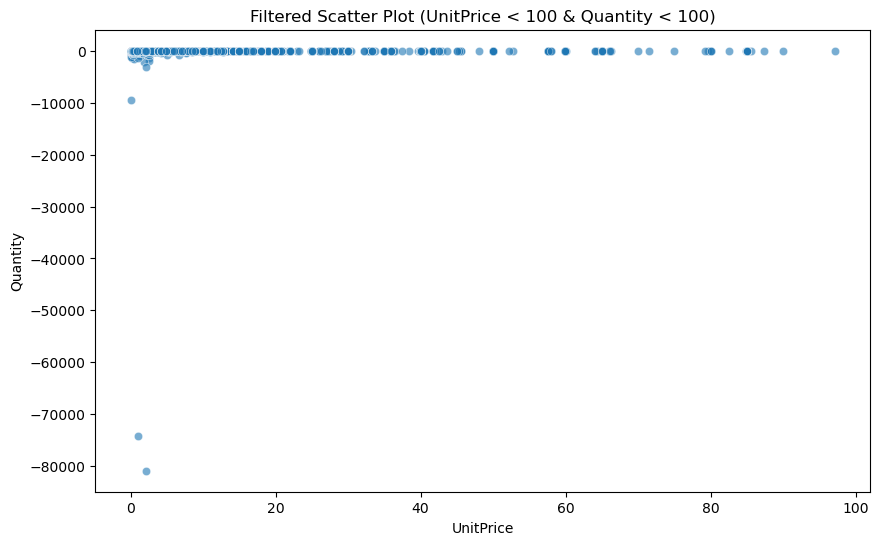

In [33]:
plt.figure(figsize=(10,6))
filtered = online_retails_copy[(online_retails_copy['UnitPrice'] < 100) & (online_retails_copy['Quantity'] < 100)]
sns.scatterplot(data=filtered, x='UnitPrice', y='Quantity', alpha=0.6)
plt.title('Filtered Scatter Plot (UnitPrice < 100 & Quantity < 100)')
plt.show()

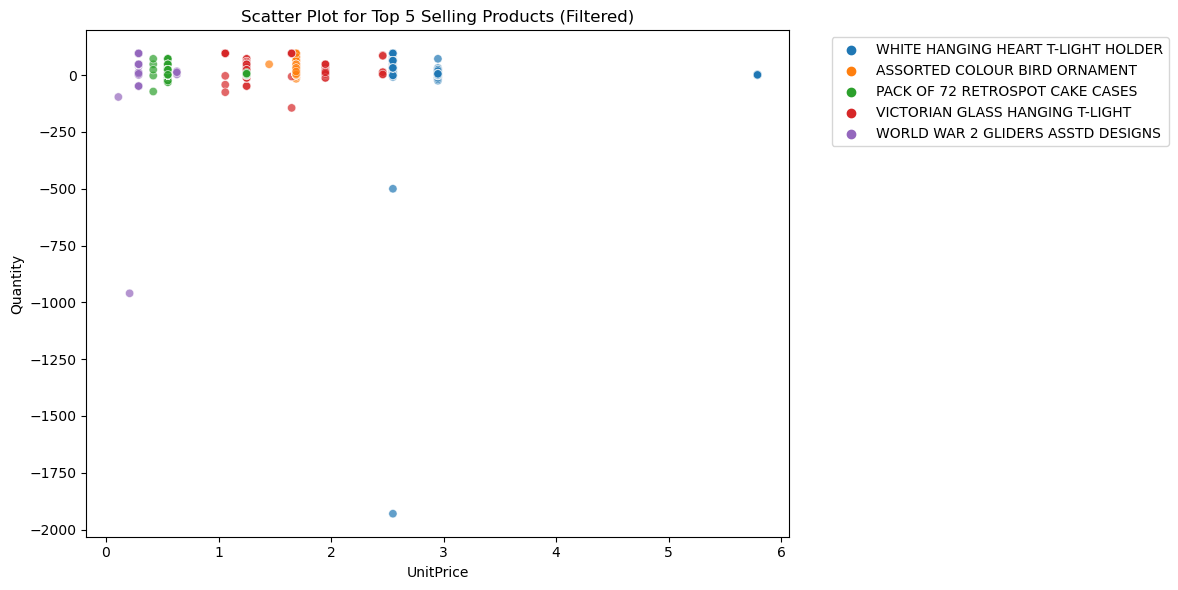

In [34]:
# 3.2.2 Get top 5 products by total quantity sold
top_products = filtered.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(5).index
filtered_top = filtered[filtered['Description'].isin(top_products)]

plt.figure(figsize=(12, 6))
sns.scatterplot(data=filtered_top, x='UnitPrice', y='Quantity', hue='Description', alpha=0.7)
plt.title('Scatter Plot for Top 5 Selling Products (Filtered)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


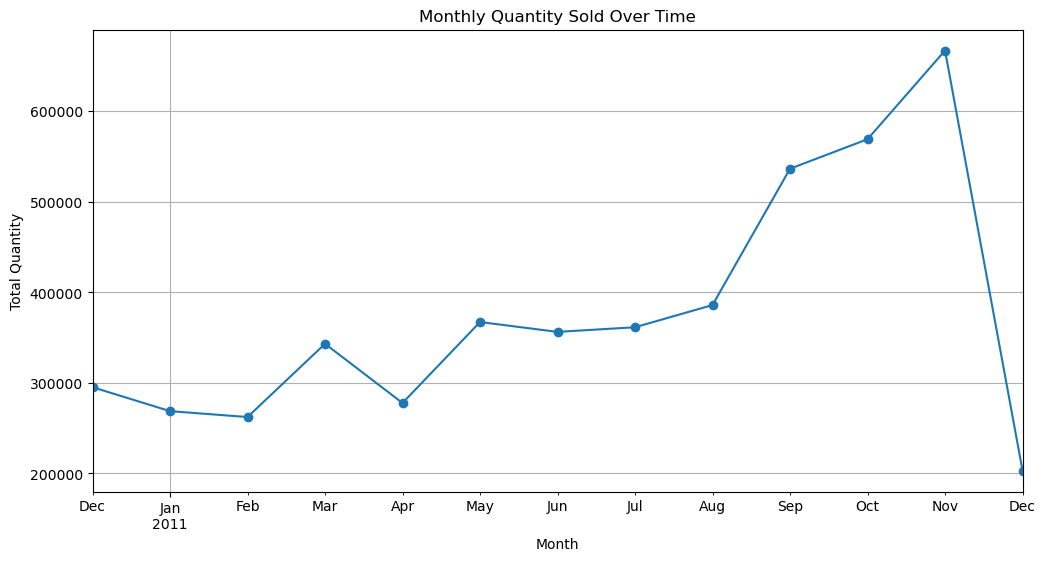

In [35]:
monthly_sales = online_retails_copy.set_index('InvoiceDate').resample('M')['Quantity'].sum()

plt.figure(figsize=(12,6))
monthly_sales.plot(marker='o')
plt.title("Monthly Quantity Sold Over Time")
plt.xlabel("Month")
plt.ylabel("Total Quantity")
plt.grid(True)
plt.show()

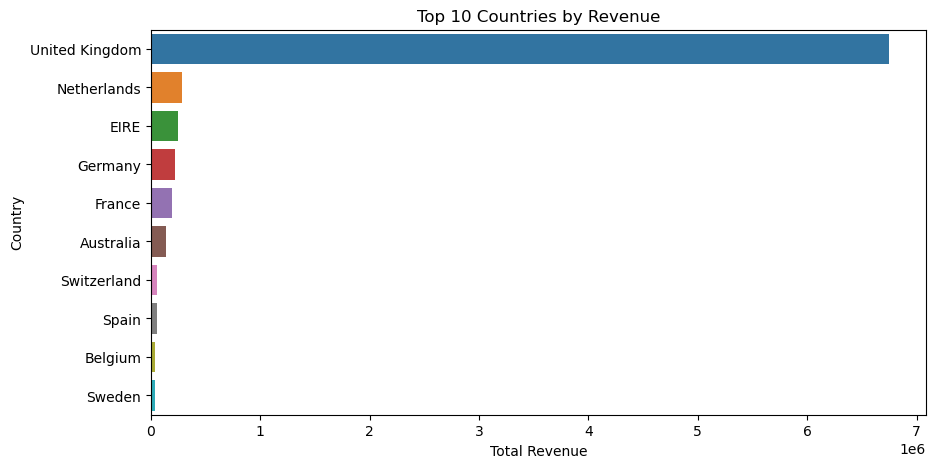

In [36]:
online_retails_copy['TotalAmount'] = online_retails_copy['Quantity'] * online_retails_copy['UnitPrice']
top_countries = online_retails_copy.groupby('Country')['TotalAmount'].sum().sort_values(ascending=False)[:10]

plt.figure(figsize=(10,5))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.show()

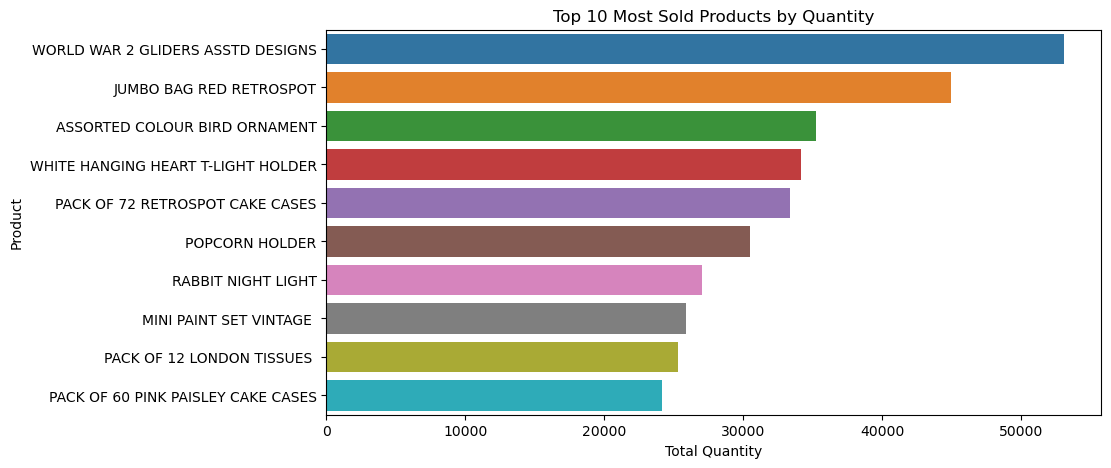

In [37]:
top_products = online_retails_copy.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 10 Most Sold Products by Quantity")
plt.xlabel("Total Quantity")
plt.ylabel("Product")
plt.show()

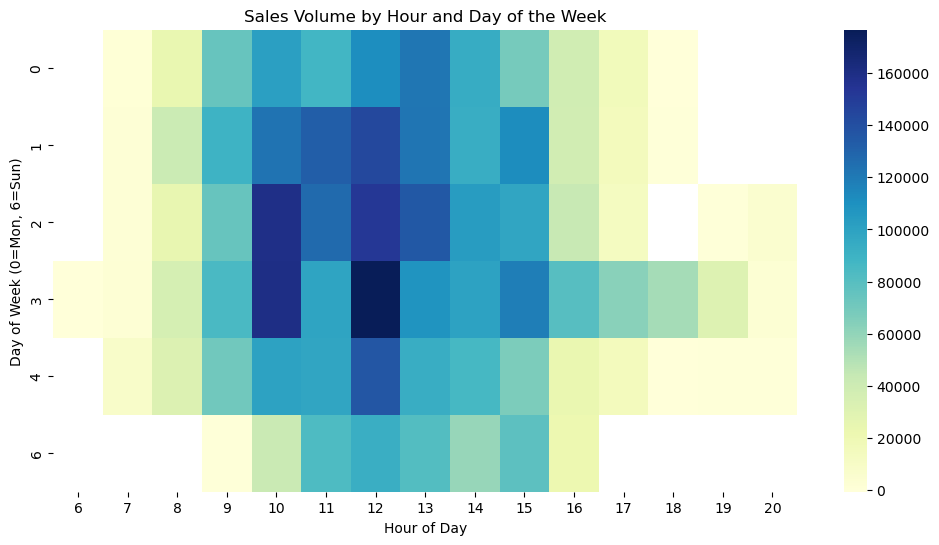

In [38]:
online_retails_copy['Hour'] = online_retails_copy['InvoiceDate'].dt.hour
online_retails_copy['DayOfWeek'] = online_retails_copy['InvoiceDate'].dt.dayofweek

heatmap_data = online_retails_copy.groupby(['DayOfWeek', 'Hour'])['Quantity'].sum().unstack()

plt.figure(figsize=(12,6))
sns.heatmap(heatmap_data, cmap='YlGnBu')
plt.title("Sales Volume by Hour and Day of the Week")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week (0=Mon, 6=Sun)")
plt.show()

In [39]:
online_retails_copy[online_retails_copy['Quantity']<0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,Hour,DayOfWeek
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom,-27.50,9,2
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom,-4.65,9,2
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom,-19.80,10,2
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,-6.96,10,2
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom,-6.96,10,2
...,...,...,...,...,...,...,...,...,...,...,...
540449,C581490,23144,ZINC T-LIGHT HOLDER STARS SMALL,-11,2011-12-09 09:57:00,0.83,14397,United Kingdom,-9.13,9,4
541541,C581499,M,Manual,-1,2011-12-09 10:28:00,224.69,15498,United Kingdom,-224.69,10,4
541715,C581568,21258,VICTORIAN SEWING BOX LARGE,-5,2011-12-09 11:57:00,10.95,15311,United Kingdom,-54.75,11,4
541716,C581569,84978,HANGING HEART JAR T-LIGHT HOLDER,-1,2011-12-09 11:58:00,1.25,17315,United Kingdom,-1.25,11,4


In [40]:
online_retails_copy = online_retails_copy.dropna(subset=['Quantity'])
online_retails_copy = online_retails_copy[online_retails_copy['Quantity'] > 0]

In [41]:
online_retails_copy[online_retails_copy['Quantity']<0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,Hour,DayOfWeek


In [42]:
online_retails_copy.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
TotalAmount           float64
Hour                    int32
DayOfWeek               int32
dtype: object

In [44]:
online_retails_copy.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
TotalAmount           float64
Hour                    int32
DayOfWeek               int32
dtype: object

In [45]:
online_retails_copy['UnitPrice'].head()

0    2.55
1    3.39
2    2.75
3    3.39
4    3.39
Name: UnitPrice, dtype: float64

In [47]:
online_retails_copy['UnitPrice'].isnull().sum()

0

In [48]:
online_retails_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 11 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392732 non-null  object        
 1   StockCode    392732 non-null  object        
 2   Description  392732 non-null  object        
 3   Quantity     392732 non-null  int64         
 4   InvoiceDate  392732 non-null  datetime64[ns]
 5   UnitPrice    392732 non-null  float64       
 6   CustomerID   392732 non-null  int64         
 7   Country      392732 non-null  object        
 8   TotalAmount  392732 non-null  float64       
 9   Hour         392732 non-null  int32         
 10  DayOfWeek    392732 non-null  int32         
dtypes: datetime64[ns](1), float64(2), int32(2), int64(2), object(4)
memory usage: 33.0+ MB


In [49]:
(online_retails_copy['UnitPrice']<0).sum()

0

In [50]:
online_retails_copy['UnitPrice'].describe()

count    392732.000000
mean          3.125596
std          22.240725
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max        8142.750000
Name: UnitPrice, dtype: float64

In [51]:
(online_retails_copy['UnitPrice']==0).sum()

40

In [52]:
online_retails_copy = online_retails_copy[online_retails_copy['UnitPrice'] > 0]

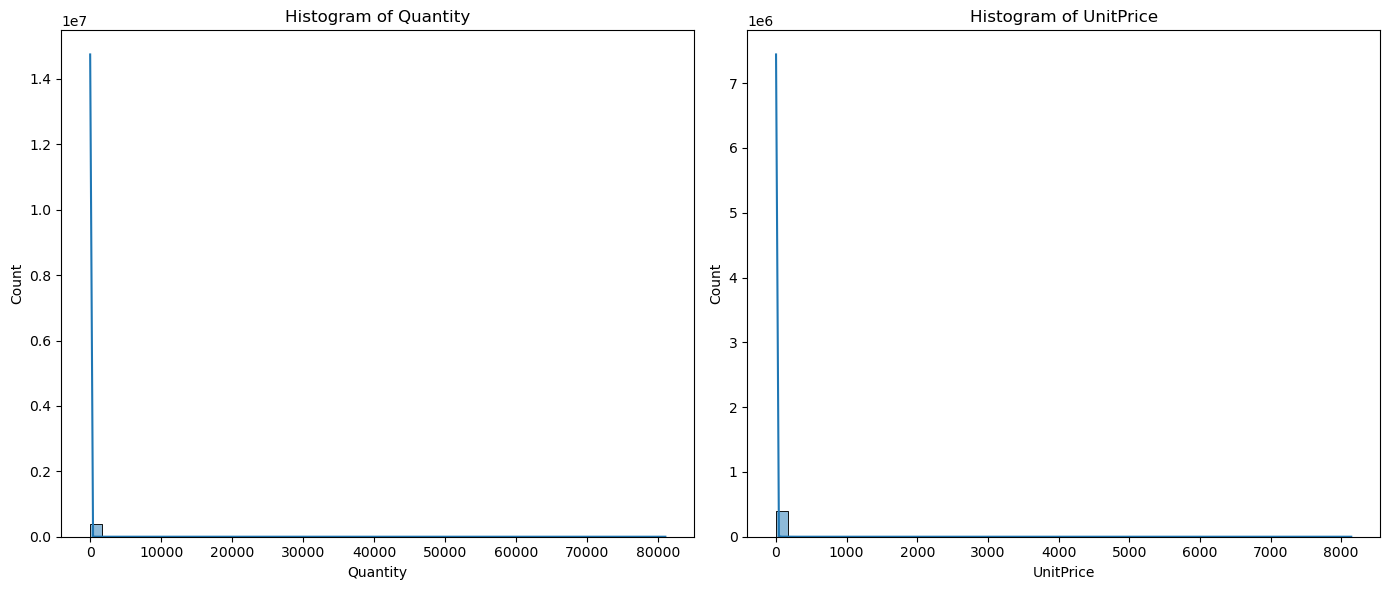

In [53]:
# Histograms for Quantity and UnitPrice distributions
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(online_retails_copy['Quantity'], bins=50, kde=True)
plt.title('Histogram of Quantity')

plt.subplot(1, 2, 2)
sns.histplot(online_retails_copy['UnitPrice'], bins=50, kde=True)
plt.title('Histogram of UnitPrice')

plt.tight_layout()
plt.show()

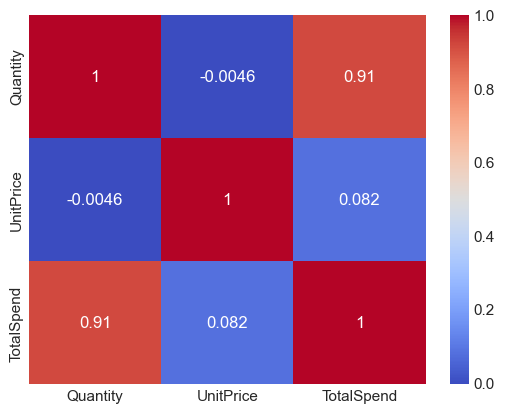

In [168]:
online_retails_copy['TotalSpend'] = online_retails_copy['Quantity'] * online_retails_copy['UnitPrice']
corr = online_retails_copy[['Quantity', 'UnitPrice', 'TotalSpend']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

# Create Recency, Frequency, and Monetary (RFM) Features

In [55]:
# Define the latest date in dataset for Recency calculation
snapshot_date = online_retails_copy['InvoiceDate'].max()
# add TotalPrice column
online_retails_copy['TotalPrice'] = online_retails_copy['Quantity'] * online_retails_copy['UnitPrice']

online_retails_copy = online_retails_copy[online_retails_copy['TotalPrice'] > 0]

# Compute RFM values
rfm = online_retails_copy.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency (days since last purchase)
    'InvoiceNo': 'nunique',  # Frequency (total transactions)
    'TotalPrice': 'sum'
}).reset_index()

# Rename columns
rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

# Display RFM data
print(rfm.head(10))

   CustomerID  Recency  Frequency  Monetary
0       12346      325          1  77183.60
1       12347        1          7   4310.00
2       12348       74          4   1797.24
3       12349       18          1   1757.55
4       12350      309          1    334.40
5       12352       35          8   2506.04
6       12353      203          1     89.00
7       12354      231          1   1079.40
8       12355      213          1    459.40
9       12356       22          3   2811.43


### Initial RFM Feature Exploration

Before applying transformations or scaling, we visualize the distribution of Recency, Frequency, and Monetary features to understand their nature and skewness.


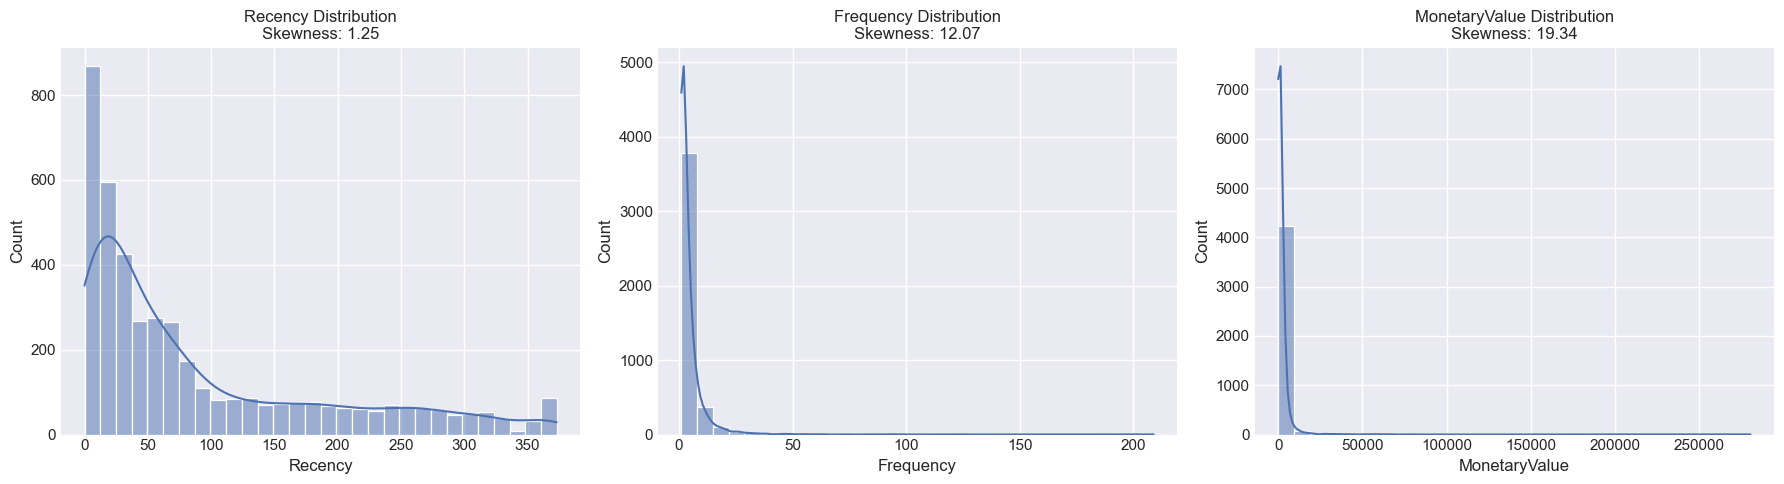

In [175]:
plt.figure(figsize=(18, 5))

for i, col in enumerate(['Recency', 'Frequency', 'MonetaryValue']):
    plt.subplot(1, 3, i+1)
    sns.histplot(rfm[col], bins=30, kde=True)
    skew = rfm[col].skew()
    plt.title(f'{col} Distribution\nSkewness: {skew:.2f}')

plt.tight_layout()
plt.show()


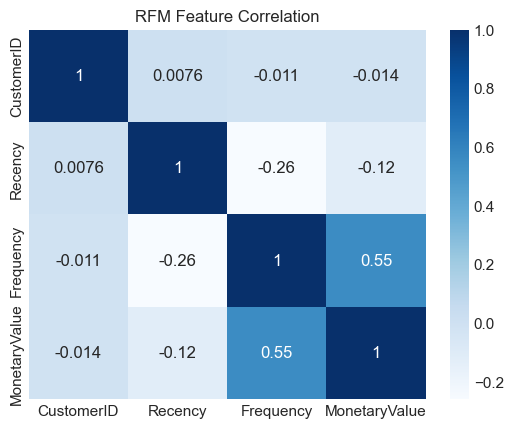

In [173]:
sns.heatmap(rfm.corr(), annot=True, cmap='Blues')
plt.title('RFM Feature Correlation')
plt.show()

# Handling Outliers in RFM

In [57]:
# Create a function to remove outliers based on IQR
def remove_outliers_columnwise(df):
    df_clean = df.copy()
    for col in ['Recency', 'Frequency', 'Monetary']:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        df_clean = df_clean[(df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)]
    return df_clean
# 1. Remove outliers column-wise
rfm_cleaned = remove_outliers_columnwise(rfm)

# 2. Restore CustomerID if it got affected during filtering
rfm_cleaned['CustomerID'] = rfm.loc[rfm_cleaned.index, 'CustomerID'].values

# 3. Print new shape for confirmation
print(f"After improved outlier removal: {rfm_cleaned.shape}")


After improved outlier removal: (3604, 4)


In [58]:
print(f"Original shape: {rfm.shape}")
print(f"After removing outliers: {rfm_cleaned.shape}")

Original shape: (4338, 4)
After removing outliers: (3604, 4)


# Data Preprocessing

In [60]:
from sklearn.preprocessing import StandardScaler

# Select only RFM columns (excluding CustomerID if it's present)
rfm_values = rfm_cleaned[['Recency', 'Frequency', 'Monetary']]

# Standardize the RFM values
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_values)


# Finding the Optimal K for K-Means

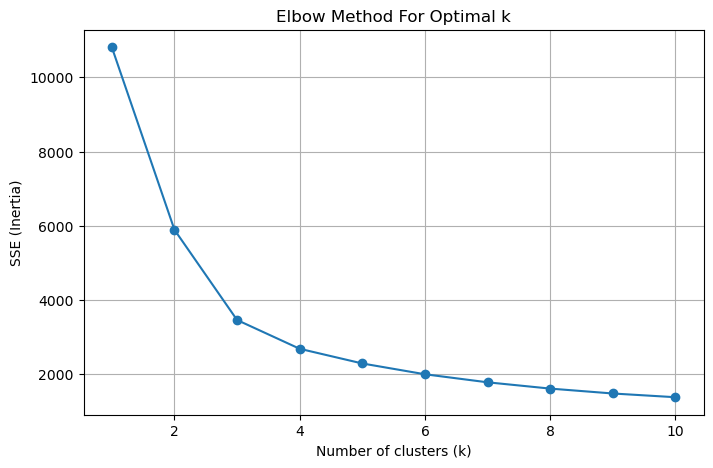

In [62]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

sse = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init= 10)
    kmeans.fit(rfm_scaled)
    sse.append(kmeans.inertia_)

# Plot the elbow
plt.figure(figsize=(8, 5))
plt.plot(k_range, sse, marker='o')
plt.xlabel('Number of clusters (k)')
plt.ylabel('SSE (Inertia)')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()


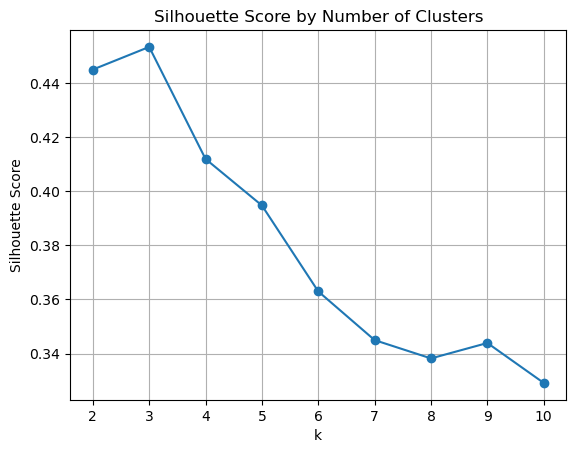

In [63]:
from sklearn.metrics import silhouette_score

sil_scores = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init= 10)
    kmeans.fit(rfm_scaled)
    sil_scores.append(silhouette_score(rfm_scaled, kmeans.labels_))

plt.plot(range(2, 11), sil_scores, marker='o')
plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


# Apply K-Means clustering

In [65]:
# Apply KMeans with optimal k
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
rfm_cleaned['Cluster'] = kmeans.fit_predict(rfm_scaled)
print(rfm_cleaned.head(10))

    CustomerID  Recency  Frequency  Monetary  Cluster
2        12348       74          4   1797.24        1
3        12349       18          1   1757.55        0
4        12350      309          1    334.40        2
5        12352       35          8   2506.04        1
6        12353      203          1     89.00        2
7        12354      231          1   1079.40        2
8        12355      213          1    459.40        2
9        12356       22          3   2811.43        1
11       12358        1          2   1168.06        0
13       12360       51          3   2662.06        1


In [66]:
cluster_profiles = rfm_cleaned.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)
print(cluster_profiles)

         Recency  Frequency  Monetary
Cluster                              
0          48.56       2.03    556.25
1          36.18       5.69   1844.40
2         226.94       1.49    403.20


# Evaluate clustering performance

In [68]:
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
from sklearn.metrics import calinski_harabasz_score
# Compute different evaluation scores
silhouette_avg = silhouette_score(rfm_scaled, rfm_cleaned['Cluster'])
davies_bouldin = davies_bouldin_score(rfm_scaled, rfm_cleaned['Cluster'])
calinski_harabasz = calinski_harabasz_score(rfm_scaled, rfm_cleaned['Cluster'])

# Store scores
evaluation_scores = {
    "Silhouette Score": silhouette_avg,
    "Davies-Bouldin Index": davies_bouldin,
    "Calinski-Harabasz Score": calinski_harabasz
}

# Print scores
print(evaluation_scores)

{'Silhouette Score': 0.45331530461677544, 'Davies-Bouldin Index': 0.777365419435965, 'Calinski-Harabasz Score': 3833.060257669832}


In [69]:
cluster_summary = rfm_cleaned.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Count'})

print(cluster_summary)


            Recency  Frequency     Monetary  Count
Cluster                                           
0         48.563598   2.028739   556.254733   1879
1         36.178266   5.688645  1844.403529    819
2        226.943709   1.491170   403.202461    906


# visualize customer segments and RFM

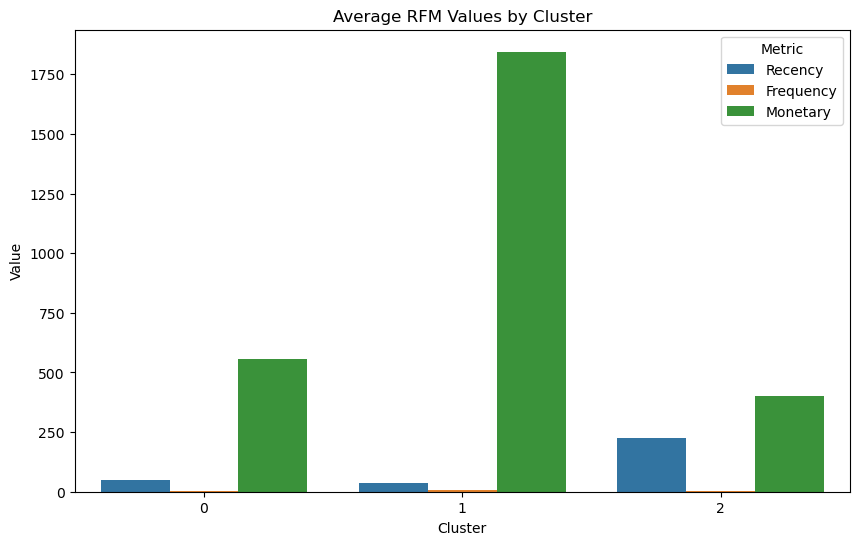

In [71]:
# 3.3.2 Create average RFM values per cluster
rfm_agg = rfm_cleaned.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).reset_index()

# Melt for seaborn
rfm_melted = pd.melt(rfm_agg, id_vars='Cluster', var_name='Metric', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(data=rfm_melted, x='Cluster', y='Value', hue='Metric')
plt.title('Average RFM Values by Cluster')
plt.show()


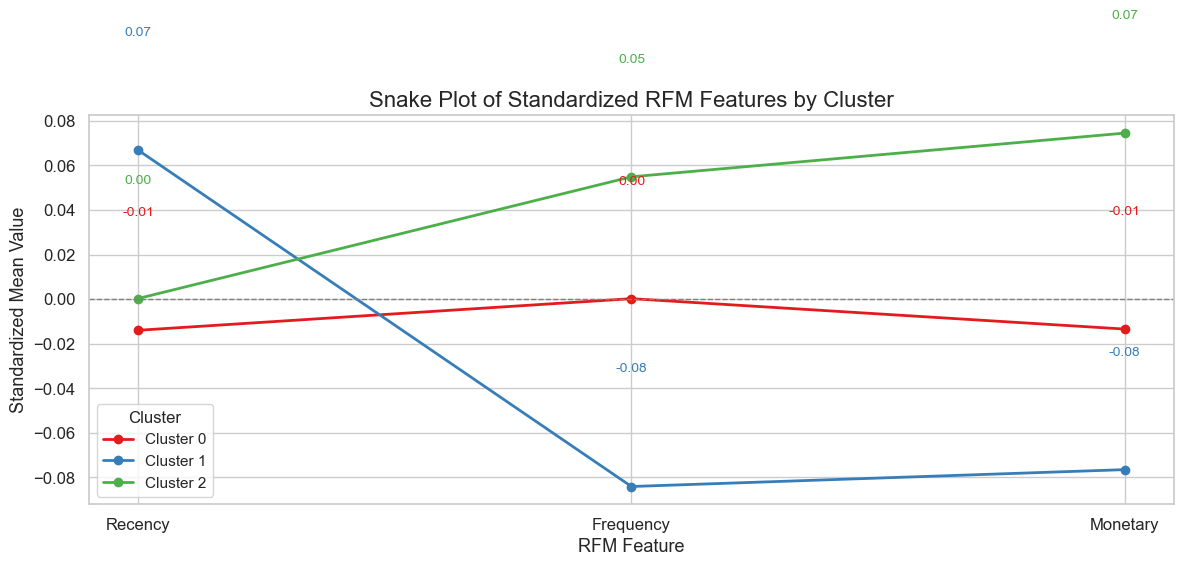

In [72]:
# Normalize the RFM features again for plotting
rfm_normalized = pd.DataFrame(rfm_scaled, columns=['Recency', 'Frequency', 'Monetary'])
rfm_normalized['Cluster'] = rfm_cleaned['Cluster']

# Group by cluster and calculate mean
snake_data = rfm_normalized.groupby('Cluster').mean()

# Set plot style
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))

# Define color palette
colors = sns.color_palette("Set1", n_colors=len(snake_data.index))

# Plot each cluster
for idx, cluster in enumerate(snake_data.index):
    values = snake_data.loc[cluster]
    plt.plot(snake_data.columns, values, label=f'Cluster {int(cluster)}', marker='o', linewidth=2, color=colors[idx])
    
    # Add annotation for each point
    for i, val in enumerate(values):
        plt.text(i, val + 0.05, f"{val:.2f}", ha='center', va='bottom', fontsize=10, color=colors[idx])

# Reference line at 0
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

# Title and labels
plt.title('Snake Plot of Standardized RFM Features by Cluster', fontsize=16)
plt.xlabel('RFM Feature', fontsize=13)
plt.ylabel('Standardized Mean Value', fontsize=13)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Cluster', title_fontsize=12, fontsize=11, loc='best')

plt.tight_layout()
plt.show()

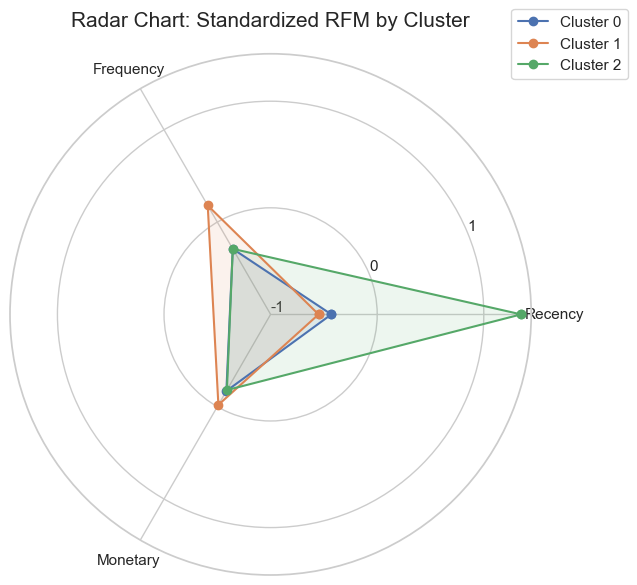

In [73]:
# Snake plot standardized data (z-scores)
snake_plot_data = {
    'Cluster 0': [-0.43, -0.29, -0.17],
    'Cluster 1': [-0.55, 0.18, -0.02],
    'Cluster 2': [1.35, -0.29, -0.18]
}

# RFM labels
labels = ['Recency', 'Frequency', 'Monetary']
num_vars = len(labels)

# Create angles for the radar chart (one per variable)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

# Create radar plot
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw=dict(polar=True))

# Plot each cluster
for cluster, values in snake_plot_data.items():
    values += values[:1]  # Complete the loop
    ax.plot(angles, values, label=cluster, marker='o')
    ax.fill(angles, values, alpha=0.1)

# Set labels and title
ax.set_title("Radar Chart: Standardized RFM by Cluster", size=15, pad=20)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels)
ax.set_yticks([-1, 0, 1])
ax.set_yticklabels(['-1', '0', '1'])

# Add legend
ax.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))

plt.tight_layout()
plt.show()

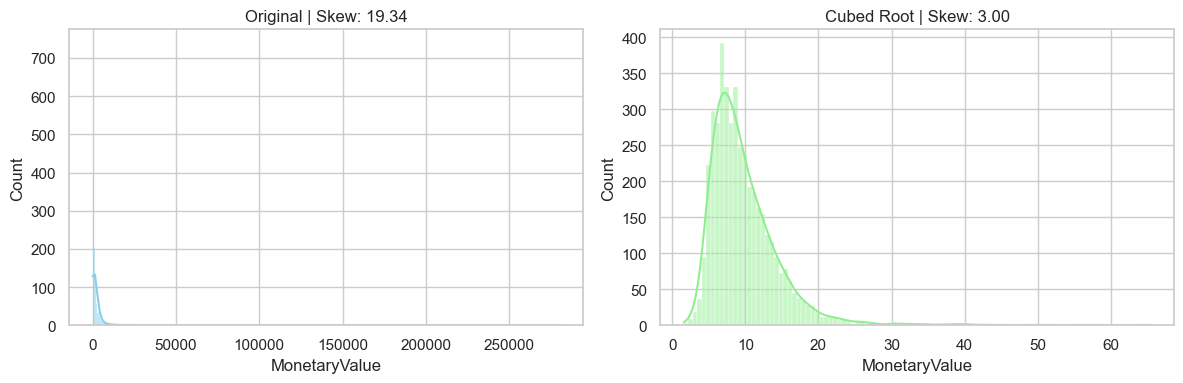

In [74]:
rfm = rfm.rename(columns={'Monetary': 'MonetaryValue'})

# Compare raw vs transformed distributions
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(rfm['MonetaryValue'], kde=True, ax=ax[0], color='skyblue')
ax[0].set_title(f"Original | Skew: {rfm['MonetaryValue'].skew():.2f}")

sns.histplot(np.cbrt(rfm['MonetaryValue']), kde=True, ax=ax[1], color='lightgreen')
ax[1].set_title(f"Cubed Root | Skew: {np.cbrt(rfm['MonetaryValue']).skew():.2f}")

plt.tight_layout()
plt.show()

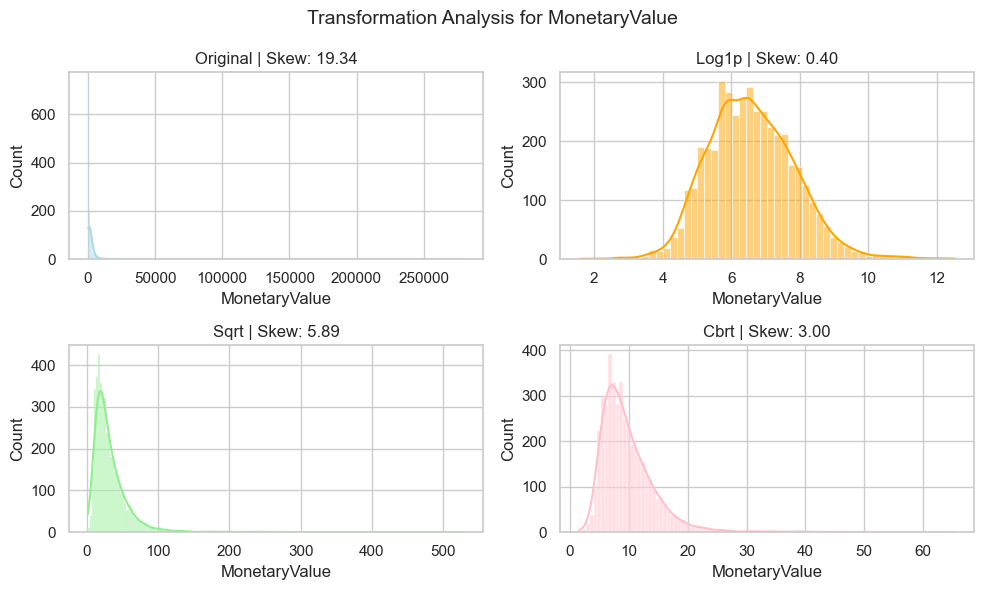

In [75]:
def analyze_skewness_no_scipy(df, column):
    fig, ax = plt.subplots(2, 2, figsize=(10, 6))
    
    sns.histplot(df[column], kde=True, ax=ax[0,0], color='lightblue')
    ax[0,0].set_title(f'Original | Skew: {df[column].skew():.2f}')
    
    sns.histplot(np.log1p(df[column]), kde=True, ax=ax[0,1], color='orange')
    ax[0,1].set_title(f'Log1p | Skew: {np.log1p(df[column]).skew():.2f}')
    
    sns.histplot(np.sqrt(df[column]), kde=True, ax=ax[1,0], color='lightgreen')
    ax[1,0].set_title(f'Sqrt | Skew: {np.sqrt(df[column]).skew():.2f}')
    
    sns.histplot(np.cbrt(df[column]), kde=True, ax=ax[1,1], color='pink')
    ax[1,1].set_title(f'Cbrt | Skew: {np.cbrt(df[column]).skew():.2f}')
    
    plt.suptitle(f'Transformation Analysis for {column}', fontsize=14)
    plt.tight_layout()
    plt.show()

# Usage
analyze_skewness_no_scipy(rfm, 'MonetaryValue')

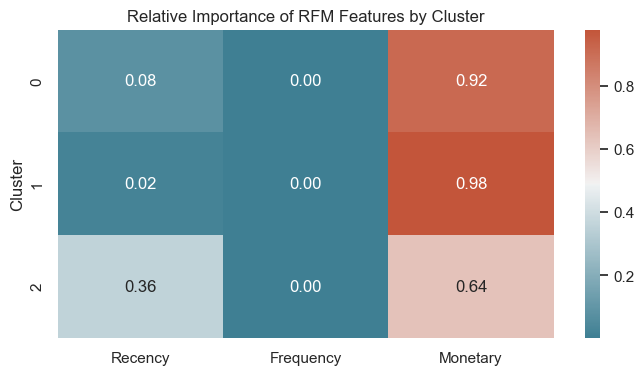

In [76]:
relative_imp = rfm_cleaned.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

# Normalize (row-wise)
relative_imp_norm = relative_imp.div(relative_imp.sum(axis=1), axis=0)

# Plot heatmap
plt.figure(figsize=(8, 4))
plt.title('Relative Importance of RFM Features by Cluster')
sns.heatmap(relative_imp_norm, annot=True, cmap=sns.diverging_palette(220, 20, as_cmap=True), fmt=".2f")
plt.show()

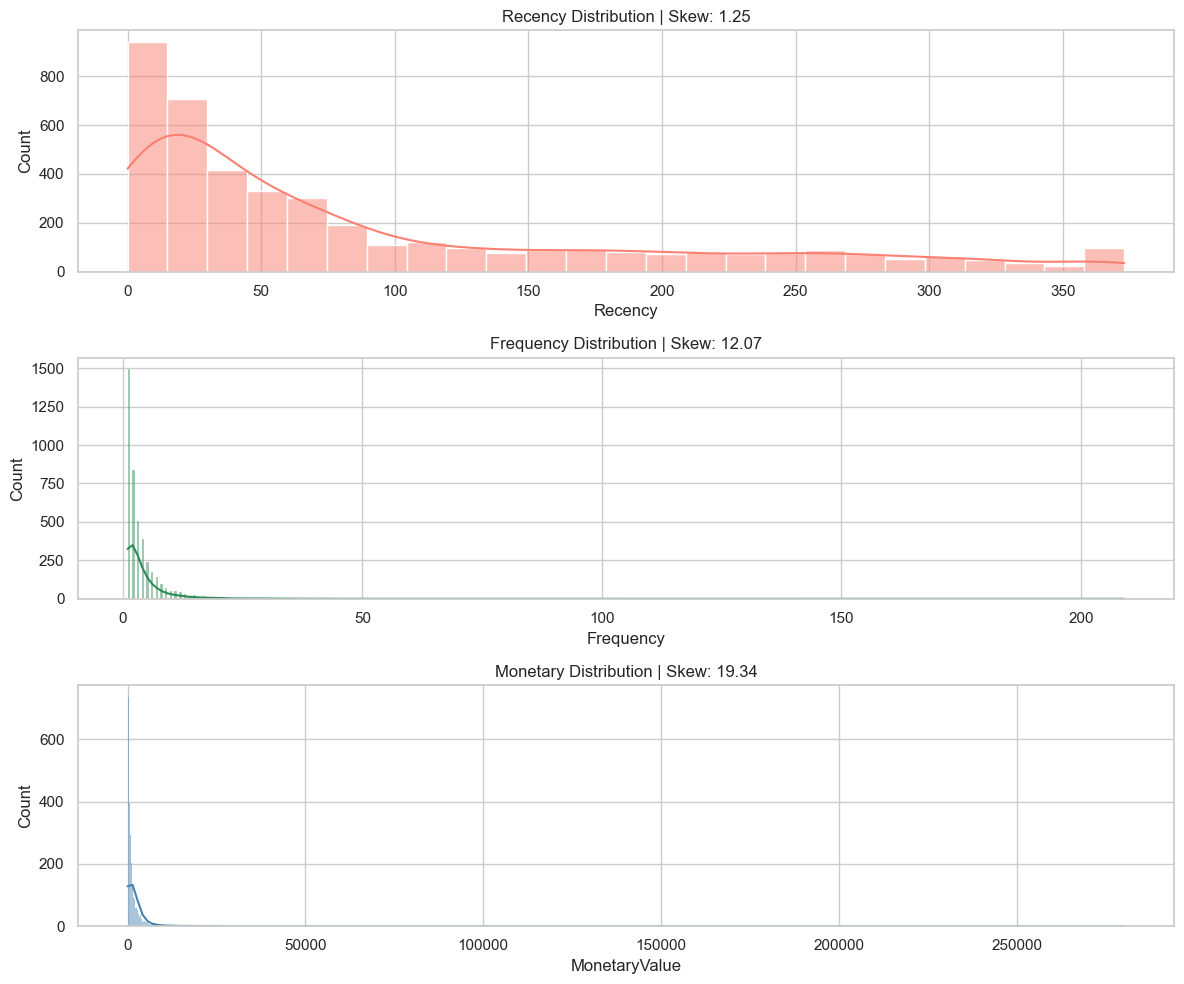

In [77]:
plt.figure(figsize=(12, 10))

plt.subplot(3, 1, 1)
sns.histplot(rfm['Recency'], kde=True, color='salmon')
plt.title(f"Recency Distribution | Skew: {rfm['Recency'].skew():.2f}")

plt.subplot(3, 1, 2)
sns.histplot(rfm['Frequency'], kde=True, color='seagreen')
plt.title(f"Frequency Distribution | Skew: {rfm['Frequency'].skew():.2f}")

plt.subplot(3, 1, 3)
sns.histplot(rfm['MonetaryValue'], kde=True, color='steelblue')
plt.title(f"Monetary Distribution | Skew: {rfm['MonetaryValue'].skew():.2f}")

plt.tight_layout()
plt.show()

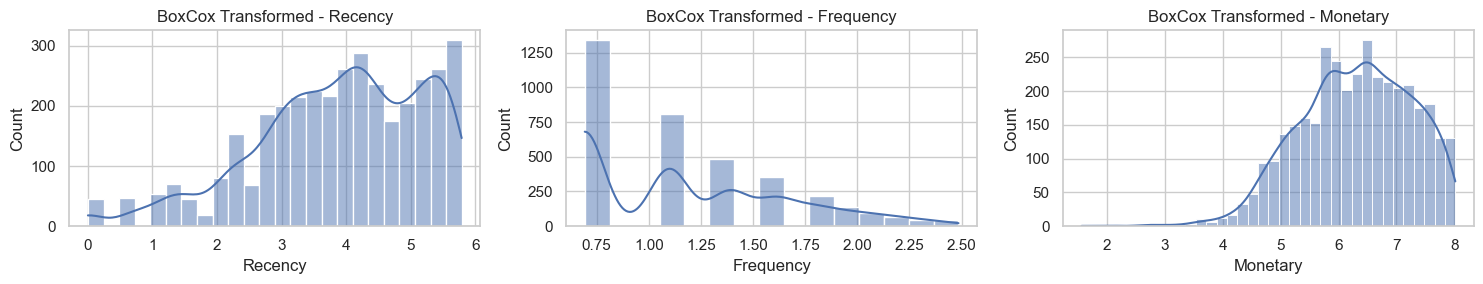

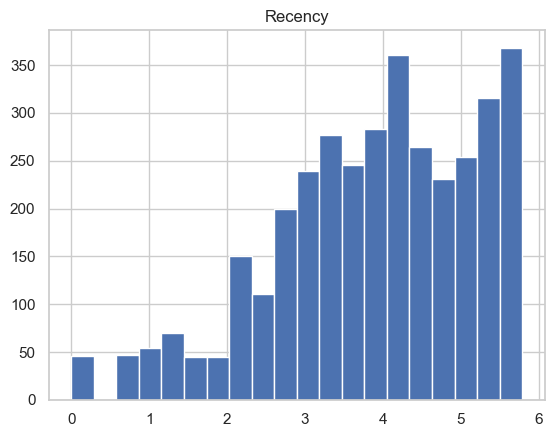

In [78]:
import math
# print('rfm cleaned', rfm_cleaned)
# Copy the original data
rfm_cleaned_logT = rfm_cleaned.copy()
rfm_cleaned_sqrtT = rfm_cleaned.copy()
rfm_cleaned_cbrtT = rfm_cleaned.copy()
rfm_cleaned_bxcxT = rfm_cleaned.copy()

# Select only numeric columns for transformation
numeric_cols = rfm_cleaned.select_dtypes(include='number').columns

# Apply transformations
for i in numeric_cols:
    rfm_cleaned_logT[i] = np.log1p(rfm_cleaned[i].clip(lower=0))
    rfm_cleaned_sqrtT[i] = np.sqrt(rfm_cleaned[i].clip(lower=0))
    rfm_cleaned_cbrtT[i] = np.cbrt(rfm_cleaned[i])
    if i != 'MonetaryValue':
        rfm_cleaned_bxcxT[i] = np.log1p(rfm_cleaned[i].clip(lower=0))

# Select features to plot (excluding identifiers)
nf = [col for col in numeric_cols if col != 'CustomerID' and col != 'Cluster']
# print("Columns selected for plotting (nf):", nf)


# Check for any NaN or infinite values after transformation
# print("NaNs in Box-Cox-like (log) transformed data:")
# print(rfm_cleaned_bxcxT[nf].isna().sum())

# print("\nInfs in Box-Cox-like (log) transformed data:")
# print(np.isinf(rfm_cleaned_bxcxT[nf]).sum())

# print(rfm_cleaned_bxcxT.columns)
# print(rfm_cleaned_bxcxT.head())

# print(rfm_cleaned_bxcxT.shape)
# print(rfm_cleaned_bxcxT.isna().sum())



# Plot Box-Cox transformed distributions dynamically
rows = math.ceil(len(nf) / 3)
plt.figure(figsize=[15, 3 * rows])
for c in range(len(nf)):
    plt.subplot(rows, 3, c + 1)
    sns.histplot(rfm_cleaned_bxcxT[nf[c]], kde=True)
    plt.title(f'BoxCox Transformed - {nf[c]}')

plt.tight_layout()
plt.show()

plt.hist(rfm_cleaned_bxcxT['Recency'], bins=20)
plt.title('Recency')
plt.show()


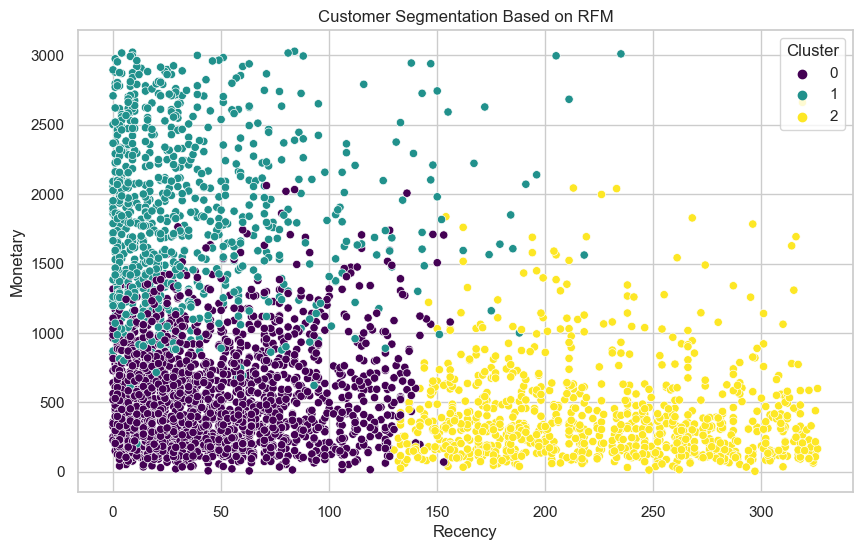

In [79]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=rfm_cleaned['Recency'], y=rfm_cleaned['Monetary'], hue=rfm_cleaned['Cluster'], palette='viridis')
plt.title('Customer Segmentation Based on RFM')
plt.show()

# Predict customer segments for new customers

In [81]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. Fit the scaler on RFM values (excluding CustomerID & Cluster)
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[['Recency', 'Frequency', 'MonetaryValue']])

# 2. Fit KMeans model (if not already fitted)
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init= 10)
kmeans.fit(rfm_scaled)  # trained

# 3. Now define the new customer
new_customer = np.array([[10, 5, 500]])  # Example input

def predict_customer_cluster(recency, frequency, monetary, scaler, kmeans, use_log=False):
    customer = pd.DataFrame([[recency, frequency, monetary]], columns=['Recency', 'Frequency', 'MonetaryValue'])
    if use_log:
        customer = np.log1p(customer)
    customer_scaled = scaler.transform(customer)
    cluster = kmeans.predict(customer_scaled)
    return cluster[0]

# Example:
cluster = predict_customer_cluster(10, 5, 500, scaler, kmeans, use_log=False)
print(f"Predicted cluster: {cluster}")
cluster_log = predict_customer_cluster(10, 5, 500, scaler, kmeans, use_log=True)
print(f"Predicted cluster_log transform data: {cluster_log}")

cluster2 = predict_customer_cluster(50, 5, 800, scaler, kmeans, use_log=False)
print(f"Predicted cluster for cluster2 data: {cluster2}")
cluster2_log = predict_customer_cluster(50, 5, 800, scaler, kmeans, use_log=False)
print(f"Predicted cluster for cluster2 log transform data: {cluster2_log}")

Predicted cluster: 1
Predicted cluster_log transform data: 1
Predicted cluster for cluster2 data: 1
Predicted cluster for cluster2 log transform data: 1


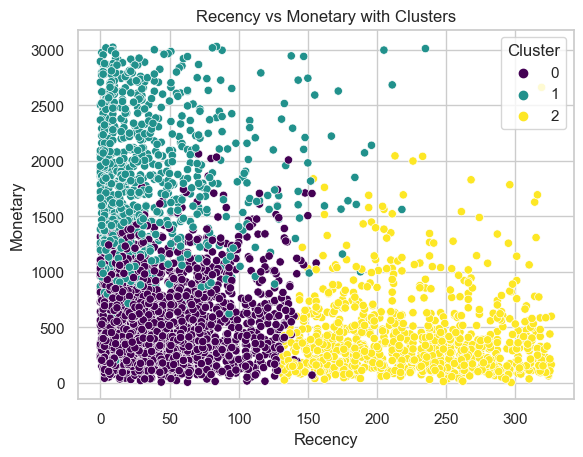

In [82]:
sns.scatterplot(data=rfm_cleaned, x='Recency', y='Monetary', hue='Cluster', palette='viridis')
plt.title("Recency vs Monetary with Clusters")
plt.show()

C:\Users\Acer\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


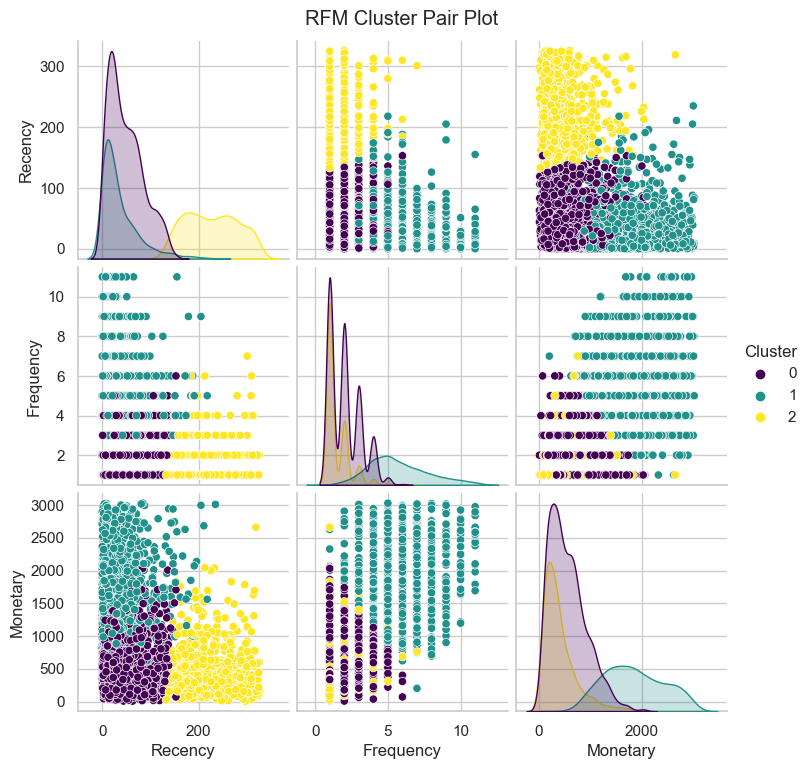

In [83]:
# B. Pairplot
sns.pairplot(rfm_cleaned[['Recency', 'Frequency', 'Monetary', 'Cluster']], hue='Cluster', palette='viridis')
plt.suptitle("RFM Cluster Pair Plot", y=1.02)
plt.show()

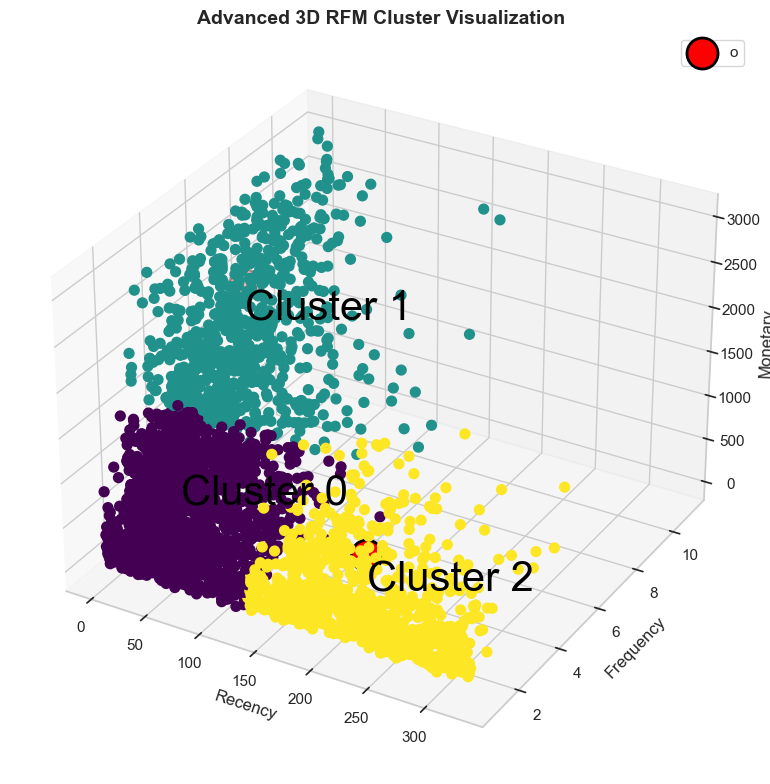

In [84]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Calculate centroids
centroids = rfm_cleaned.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().reset_index()

# Plot setup
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot cluster points (semi-transparent)
scatter = ax.scatter(
    rfm_cleaned['Recency'],
    rfm_cleaned['Frequency'],
    rfm_cleaned['Monetary'],
    c=rfm_cleaned['Cluster'],
    cmap='viridis',
    s=50,
    alpha=1
)

# Plot centroids with bold red 'X'
ax.scatter(
    centroids['Recency'],
    centroids['Frequency'],
    centroids['Monetary'] + 500,  # Z offset for visibility
    c='red',
    marker='o',
    s=500,
    edgecolors='black',
    linewidths=2,
    label='o'
)

# Annotate each centroid with its cluster number
for i, row in centroids.iterrows():
    ax.text(
        row['Recency'], row['Frequency'], row['Monetary'] + 100,
        f"Cluster {int(row['Cluster'])}",
        color='black',
        fontsize=30,
        # fontweight='bold'
    )

# Axis labels and title
ax.set_xlabel('Recency', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_zlabel('Monetary', fontsize=12)
ax.set_title('Advanced 3D RFM Cluster Visualization', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper right')
plt.style.use('seaborn-v0_8-darkgrid')
# Show plot
plt.tight_layout()
plt.show()

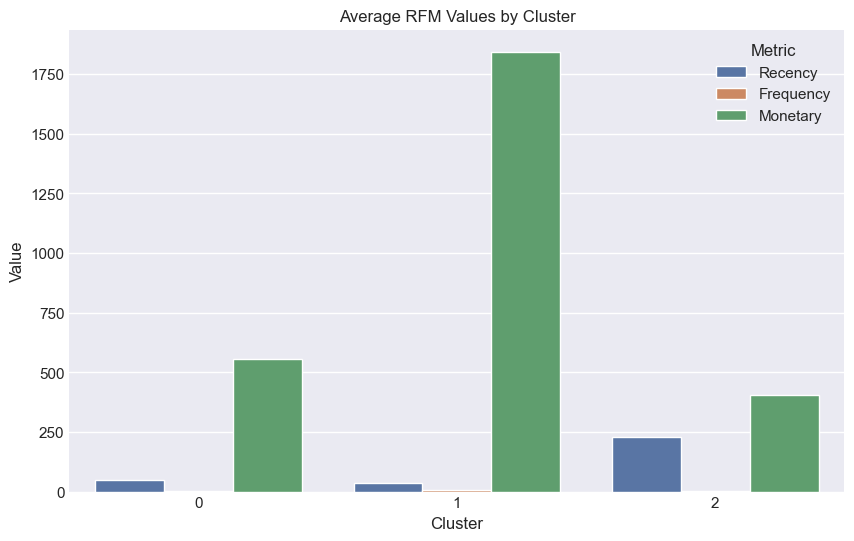

In [85]:
# 3.3.2 Create average RFM values per cluster
rfm_agg = rfm_cleaned.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).reset_index()

# Melt for seaborn
rfm_melted = pd.melt(rfm_agg, id_vars='Cluster', var_name='Metric', value_name='Value')

plt.figure(figsize=(10, 6))
sns.barplot(data=rfm_melted, x='Cluster', y='Value', hue='Metric')
plt.title('Average RFM Values by Cluster')
plt.show()


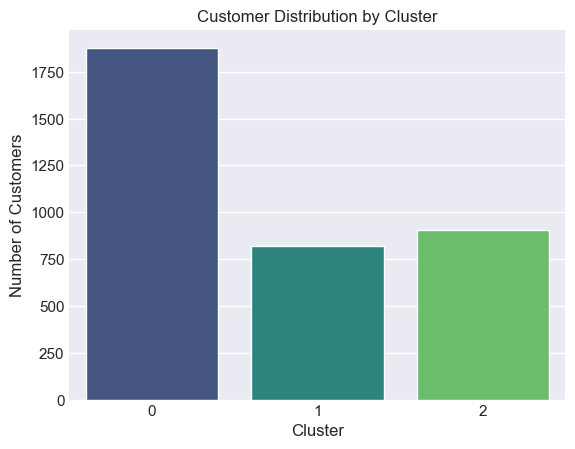

In [86]:
# E. Countplot
sns.countplot(data=rfm_cleaned, x='Cluster', palette='viridis')
plt.title('Customer Distribution by Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

In [87]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


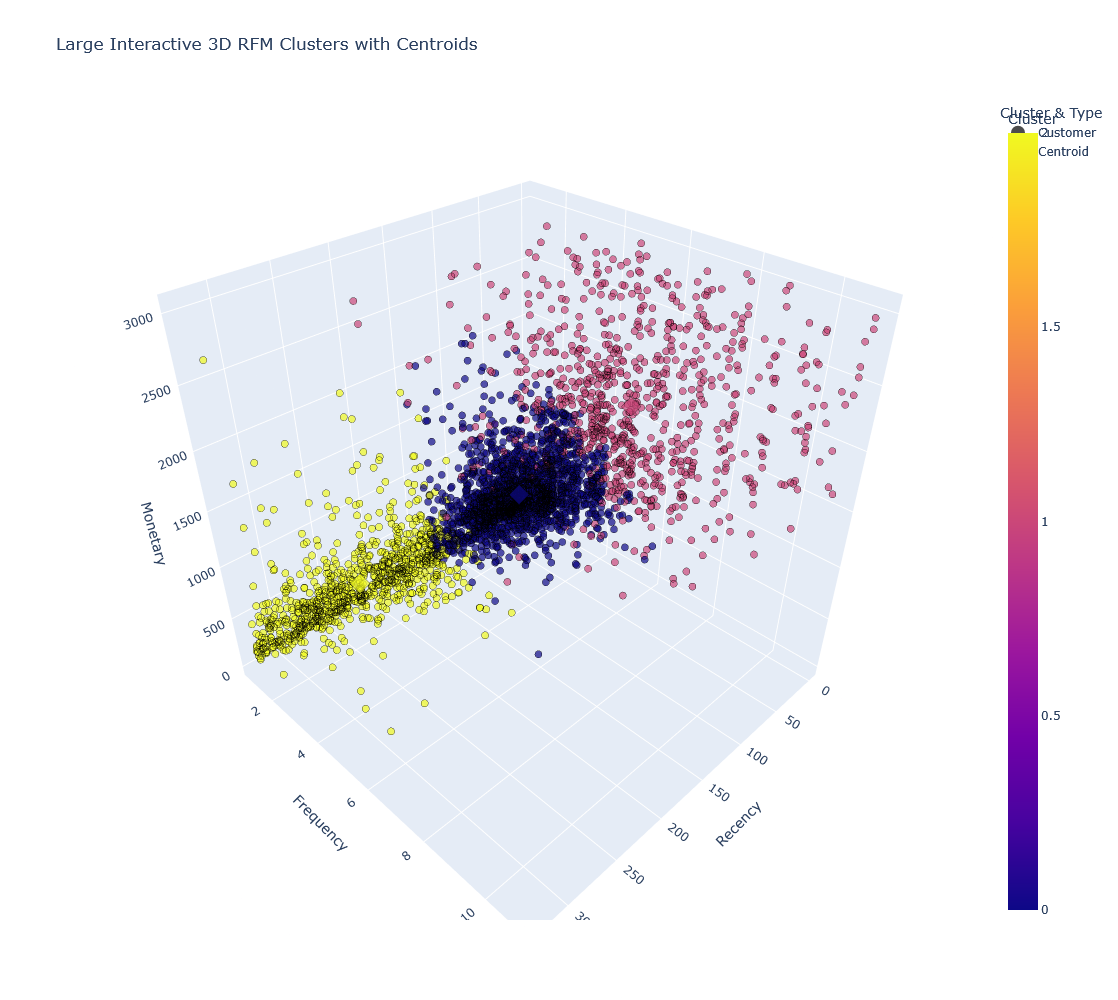

In [88]:
import plotly.express as px
import pandas as pd

# Assume rfm_cleaned has 'Recency', 'Frequency', 'Monetary', and 'Cluster'
# Calculate centroids
centroids = rfm_cleaned.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().reset_index()
centroids['Type'] = 'Centroid'

# Add 'Type' to customer points
rfm_cleaned['Type'] = 'Customer'

# Add manual size column
rfm_cleaned['Size'] = 4
centroids['Size'] = 12

# Combine data
combined_df = pd.concat([
    rfm_cleaned[['Recency', 'Frequency', 'Monetary', 'Cluster', 'Type', 'Size']],
    centroids[['Recency', 'Frequency', 'Monetary', 'Cluster', 'Type', 'Size']]
])

# Plot
fig = px.scatter_3d(
    combined_df,
    x='Recency',
    y='Frequency',
    z='Monetary',
    color='Cluster',
    symbol='Type',   # Different symbol for centroids
    size='Size',     # Use the Size column for visual emphasis
    opacity=0.7,
    title='Interactive 3D RFM Clusters with Centroids'
)

fig.update_traces(marker=dict(line=dict(width=1, color='black')))
# fig.update_layout(
#     legend=dict(title='Cluster & Type'),
#     scene=dict(
#         xaxis_title='Recency',
#         yaxis_title='Frequency',
#         zaxis_title='Monetary'
#     )
# )

fig.update_layout(
    width=1600,  # pixels
    height=1000,
    scene=dict(
        xaxis_title='Recency',
        yaxis_title='Frequency',
        zaxis_title='Monetary'
    ),
    title='Large Interactive 3D RFM Clusters with Centroids',
    legend=dict(title='Cluster & Type')
)


fig.show()